# MiniLM 교차 플랫폼 알고리즘 문제 파일럿

이 실행은 고정된 MiniLM 모델로 90개 영어 문제 요약을 임베딩하고, 같은 입력의 TF-IDF와 비교합니다. 이는 작은 검토 주석 집합에 대한 오프라인 진단이며 전체 문제 카탈로그 검색 성능이나 학습 효과를 측정하지 않습니다.

## 핵심 결과

고정 revision MiniLM을 검토된 영문 제목·요약 90개에 실행했습니다. 코호트는 {"atcoder": 20, "codeforces": 10, "leetcode": 60}이며, 모델 backend·최초 관련 import는 5.012초였습니다. 두 입력 변형은 각각 MiniLM 벡터를 만들었고, encode 시간은 title+rationale 0.166초, title only 0.058초입니다.

이 수치는 해당 개발 머신의 CPU 실행 기록이며 OCI나 운영 비용 추정이 아닙니다.

title_rationale에서 검토 후보만 대상으로 한 평균 nDCG@5: minilm 0.877 (ranking groups 3/query groups 35), tfidf 1.000 (ranking groups 3/query groups 35)

title_only에서 검토 후보만 대상으로 한 평균 nDCG@5: minilm 0.877 (ranking groups 3/query groups 35), tfidf 1.000 (ranking groups 3/query groups 35)

## 실행 범위와 비용

사전 고정된 코호트는 LeetCode 60개, AtCoder 20개, Codeforces 10개입니다. 입력 필드는 제목과 기존 영어 rationale이며, 명시적 concept tag, 플랫폼, 난이도는 입력에 넣지 않습니다. 각 입력을 제목+rationale 및 제목만 사용하는 두 변형으로 계산합니다.

모델 파일은 고정 revision의 로컬 스냅샷을 사용합니다. 이 분석 단계는 API 호출과 모델 재다운로드 없이 CPU에서 동작하며 추론 비용은 로컬 CPU 시간입니다. 최초 자산 준비는 모델 다운로드와 연구용 Python 의존성 설치 비용이 별도로 듭니다. 개발 머신의 시간·메모리 수치는 OCI 자원 한도나 운영 비용의 증거가 아닙니다.

## 데이터와 방법

임베딩 유사도는 검색 제안과 별개로, 기존 검토 관계 라벨이 있는 후보만으로 TF-IDF와 MiniLM을 평가합니다. 후보가 2개 미만인 query group은 ranking 지표에서 제외되며, seed graph와 겹치는 관계 라벨도 제외합니다. 보고서에는 평가 가능한 분모와 제외 수를 함께 표시합니다. nDCG는 이 희소하게 검토된 후보 안에서만 계산하며 미검토 카탈로그 항목은 음성으로 간주하지 않습니다.

고정된 9개 예제는 세 플랫폼에서 각각 세 문제를 제시합니다. 각 플랫폼을 제외한 상위 3개는 모델 제안이지 승인된 관계가 아닙니다. PCA/t-SNE/UMAP 그림은 90개 작은 코호트의 탐색적 배치입니다. 축이나 군집 간격은 알고리즘 관계를 입증하지 않습니다.

In [1]:
from pathlib import Path
import importlib
import sys

candidates = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
ROOT = next((p for p in candidates if (p / "research/minilm_pilot/experiment.py").is_file()
             and (p / "curriculum/annotations.v1.json").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("저장소 루트와 파일럿 입력을 찾지 못했습니다")
OUTPUT = ROOT / "research/minilm_pilot"
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from research.minilm_pilot import experiment
experiment = importlib.reload(experiment)
results = experiment.run(ROOT, OUTPUT)
assert isinstance(results, dict)
print("실험 완료:", results["scope"])

실험 완료: 90 reviewed English annotations, not 21,244 downloaded metadata records or full statements


## 실제 실행 결과

모델: sentence-transformers/all-MiniLM-L6-v2 revision: 1110a243fdf4706b3f48f1d95db1a4f5529b4d41
코호트: {'atcoder': 20, 'codeforces': 10, 'leetcode': 60} | 실행 환경: {'torch': '2.9.1', 'sentence-transformers': '5.2.0', 'transformers': '4.57.3', 'numpy': '2.1.3', 'scikit-learn': '1.8.0', 'umap-learn': '0.5.9.post2'}
검토된 후보 범위에서의 ranking 결과 (미검토 후보는 음성이 아님)


,입력,방법,query groups,ranking groups,nDCG@5,Recall@10,그래프 제외 행
0,title_rationale,tfidf,35,3,1.000,1.0,22
1,title_rationale,minilm,35,3,0.877,1.0,22
2,title_only,tfidf,35,3,1.000,1.0,22
3,title_only,minilm,35,3,0.877,1.0,22


실측 자원과 토큰 길이


,입력,encode 초,벡터 MiB,토큰 중앙값,토큰 최댓값,256 초과
0,title_rationale,0.1660,0.1318,17.0,32,0
1,title_only,0.0584,0.1318,5.0,15,0


고정 9개 query의 교차 플랫폼 상위 3개 제안


,query,제목,상위 제안
0,leetcode:two-sum,Two Sum,atcoder:abc083_b (0.443) | atcoder:abc087_b (0...
1,leetcode:valid-parentheses,Valid Parentheses,codeforces:112A (0.343) | atcoder:abc072_b (0....
2,leetcode:coin-change,Coin Change,atcoder:abc087_b (0.552) | codeforces:282A (0....
3,atcoder:abc086_a,Product,leetcode:product-of-array-except-self (0.377) ...
4,atcoder:abc086_c,Traveling,leetcode:non-overlapping-intervals (0.416) | c...
5,atcoder:abc085_c,Otoshidama,leetcode:climbing-stairs (0.288) | leetcode:to...
6,codeforces:4A,Watermelon,atcoder:abc086_a (0.334) | leetcode:trapping-r...
7,codeforces:112A,Petya and Strings,leetcode:valid-anagram (0.475) | leetcode:vali...
8,codeforces:339A,Helpful Maths,atcoder:abc083_b (0.428) | atcoder:abc079_c (0...


Fixed queries, model proposals only; cosine is not relevance probability or approved relationship.
입력 hash 불변: True | peak RSS bytes: 812040192 | warnings: 8
경고 TqdmWarning × 1: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
경고 ImportWarning × 1: Tensorflow not installed; ParametricUMAP will be unavailable
경고 RuntimeWarning × 2: divide by zero encountered in matmul
나머지 경고 종류는 results.json에 보존
similarity.png


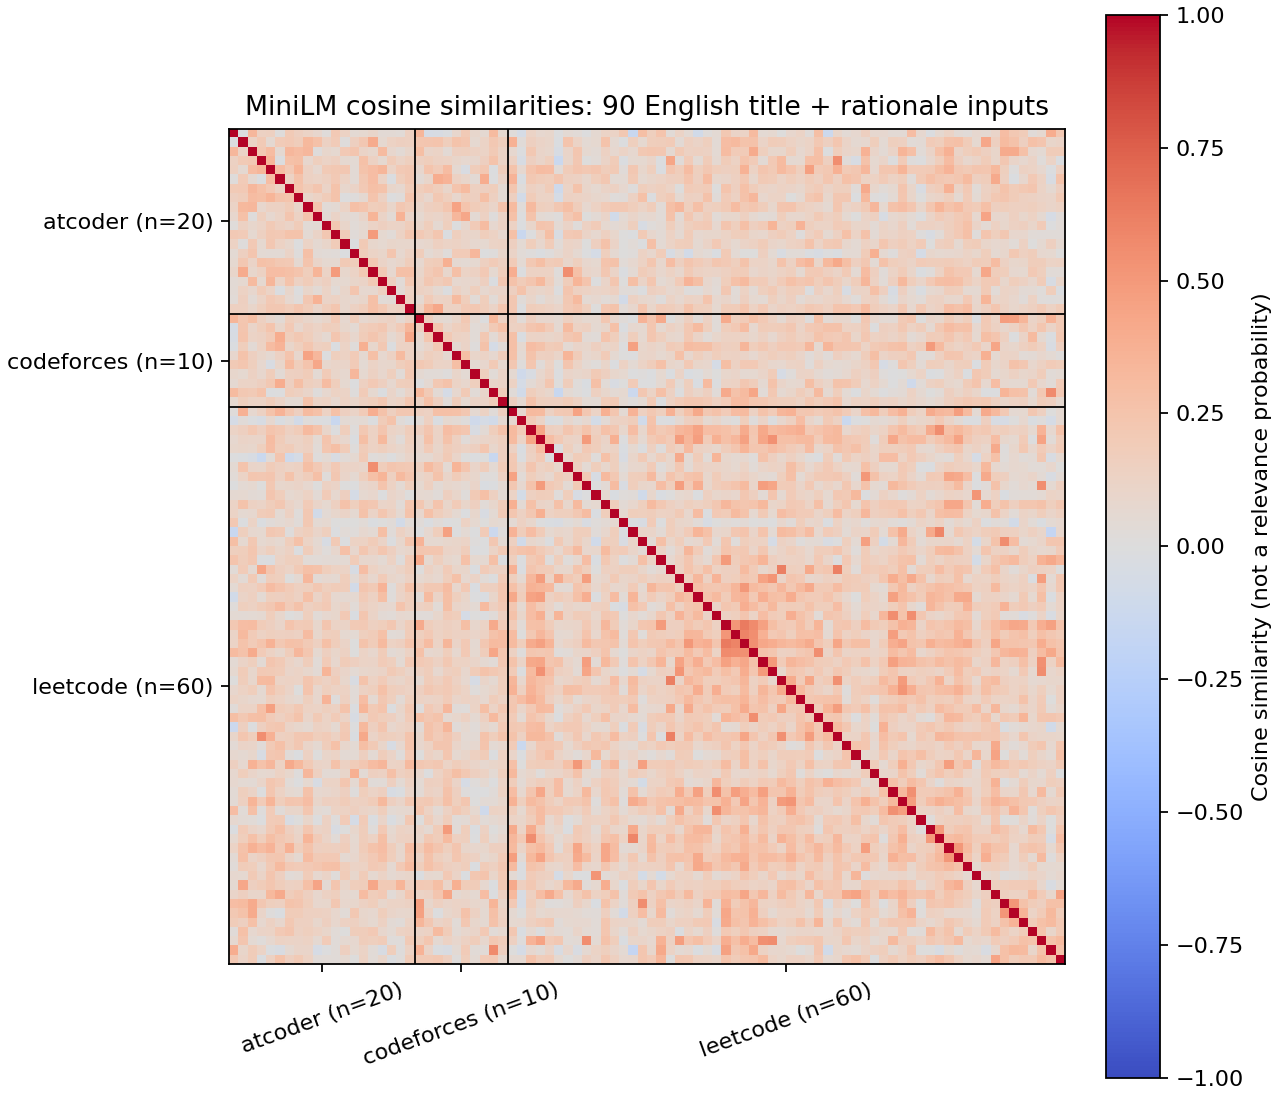

projections.png


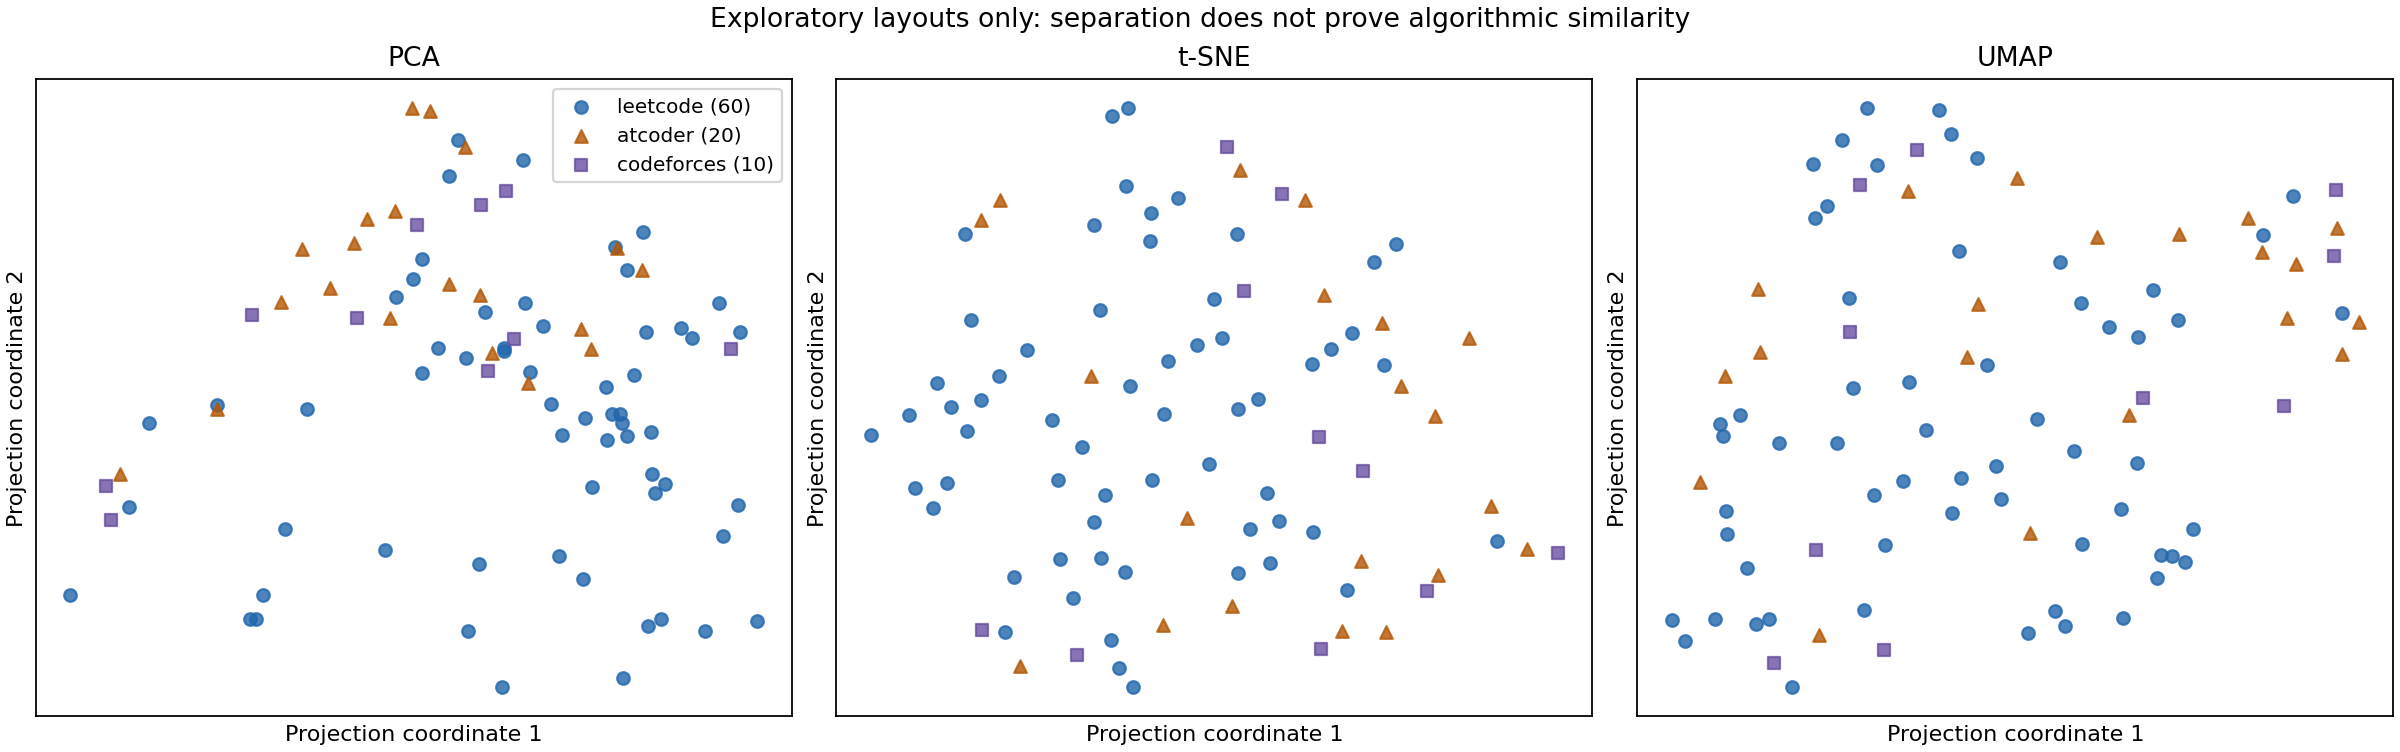

In [2]:
import pandas as pd
from IPython.display import Image, display

print("모델:", results["model"]["model_id"], "revision:", results["model"]["revision"])
print("코호트:", results["cohort_counts"], "| 실행 환경:", results["environment"])
variant_rows = []
for variant, value in results["variants"].items():
    score = value["scoring"]
    for method, metrics in score["metrics"].items():
        variant_rows.append({"입력": variant, "방법": method,
            "query groups": metrics.get("query_groups"),
            "ranking groups": metrics.get("ranking_query_groups"),
            "nDCG@5": metrics.get("ndcg_at_5"),
            "Recall@10": metrics.get("recall_at_10"),
            "그래프 제외 행": score.get("seed_graph_overlap_rows_excluded", 0)})
print("검토된 후보 범위에서의 ranking 결과 (미검토 후보는 음성이 아님)")
display(pd.DataFrame(variant_rows).round(4))

resource_rows = []
for name, value in results["variants"].items():
    tokens = value["token_lengths"]
    resource_rows.append({"입력": name, "encode 초": value["encode_seconds"],
        "벡터 MiB": value["vector_bytes"] / 2**20,
        "토큰 중앙값": tokens["median"], "토큰 최댓값": tokens["max"],
        "256 초과": tokens["over_256"]})
print("실측 자원과 토큰 길이")
display(pd.DataFrame(resource_rows).round(4))

print("고정 9개 query의 교차 플랫폼 상위 3개 제안")
example_rows = []
for example in results["cross_platform_examples"]:
    example_rows.append({"query": example["source"], "제목": example["title"],
        "상위 제안": " | ".join(f"{n['problem_key']} ({n['cosine']:.3f})"
            for n in example["neighbors"])})
display(pd.DataFrame(example_rows))
print(results["example_boundary"])

print("입력 hash 불변:", results["input_hashes_unchanged"],
      "| peak RSS bytes:", results["process_peak_rss_bytes"],
      "| warnings:", sum(w["count"] for w in results.get("warnings", [])))
for warning in results.get("warnings", [])[:3]:
    print(f"경고 {warning['category']} × {warning['count']}: {warning['message']}")
if len(results.get("warnings", [])) > 3:
    print("나머지 경고 종류는 results.json에 보존")
for name in results.get("figures", []):
    path = OUTPUT / name
    if path.is_file():
        print(name)
        display(Image(filename=str(path)))

## 해석 경계

모델은 전체 21,244개 카탈로그 메타데이터나 문제 본문이 아니라 90개 검토된 영어 annotation만 처리합니다. AtCoder 메타데이터의 출처는 공식 API가 아니라 AtCoder Problems 커뮤니티 데이터입니다. 모든 nearest-neighbor 결과는 검토가 필요한 제안입니다.

판정된 후보가 적고 seed graph 겹침을 제거하므로 nDCG/Recall은 희소한 조건부 지표입니다. 이 값을 전체 카탈로그 recall이나 일반화 성능으로 읽지 않습니다. MiniLM의 어떤 지표가 높더라도 자동 승격 근거가 되지 않으며, 현재 실험은 모델 훈련·승격을 하지 않습니다.

입력 파일 hash, 모델 manifest, 라이브러리 버전, 경고와 실행 측정값은 `results.json`에 보존합니다. 재현에 필요한 패키지는 [연구 의존성](requirements-research.txt), 모델 파일과 고정 revision은 [manifest](model.manifest.json), 데이터와 사전등록된 범위는 [파일럿 명세](../../specs/adaptive-learning/minilm-pilot.md)에 기록되어 있습니다.